# Plan-following experiment: does the released action head follow a plan it is given?
**VLA direction** · LIBERO-Object · released starVLA checkpoint `Qwen3-VL-PI-LIBERO-4in1` with a small trained add-on · 11 Nov 2026 · a diagnostic before any training of the full method

- **The question:** if the action head is told where the next grasp or release should happen, does it go there, also when that place is not where the scene usually has it? This is the half of the method that turns a plan into actions. If it fails with a perfect plan, predicting plans is pointless.
- **Real:** the demonstrations, the released VLA, the training of the add-on, the open-loop numbers and the closed-loop rollouts in the simulator.
- **ORACLE:** the plan itself. In training it comes from the demonstration; in the rollouts it comes from simulator ground truth (object position plus the average grasp point of the demonstrations). No model predicts it.
- **Not the paper's configuration:** the VLM is frozen and is the 4B model, and only a plan encoder, low-rank updates of the action head and its output layer are trained (about 31 M of 7.8 B parameters). The method itself trains the whole VLA.
- **Result in short:** given only as an extra input, the plan is ignored. Once training also shows the same frame with the plan moved elsewhere, the gripper goes to the planned grasp point in 18 of 18 rollouts with a moved target and in 27–30 of 30 that name another object, and the named object ends in the basket in 19–20 of 30 instead of 6. Relabelled actions do this as well as the consistency loss. The conclusions are in the last section.

```text
(1) demonstrations → recorded simulator states → per-step logs                   real (state replay, no dynamics)
        ↓
(2) plan input: where the next gripper event happens, relative to the gripper    ORACLE (demonstration / simulator)
        ↓
(3) training samples: the demonstration, and the same frame with a moved plan    real (built from demonstrations)
        ↓
(4) training on the frozen released checkpoint: plan encoder + low-rank updates  real (GPU queue, one shared card)
        ↓
(5) open loop on held-out demonstrations: does the chunk go where the plan says  real
        ↓
(6) closed loop: the 21 rollouts of the 10 Nov pipeline demo, now with a plan    real (plan: ORACLE)
```

<sub>To re-run on the A6000 server: `scripts/remote/fetch_libero_states.py`, `replay_libero_states.sh`, `build_plan_dataset.py` (CPU), then `run_plan_following_gpu.sh` through the GPU queue for each run (see its header), then execute this notebook.</sub>

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Video, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
sys.path.insert(0, str(ROOT))
from affordance3d.plan_dataset import load_tracks
from affordance3d.plan_input import offsets_from_json
from report import plan_following_helpers as P
from report import vla_pipeline_demo_helpers as H

set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90})
pd.set_option("display.max_colwidth", 140)

RUNS = ROOT / "runs" / "plan_following"
MEDIA = ROOT / "report" / "media"  # videos made by this notebook; tracked in git so a pull brings them
DATASET = RUNS / "dataset"                                  # six tasks of LIBERO-Object
BASELINE = ROOT / "runs" / "vla_pipeline_demo" / "rollouts"  # the released policy, 10 Nov 2026
MAIN = "+ moved plans (path loss)"
RELABELLED = "+ moved plans (relabelled actions)"
MORE = "rollouts_oracle_more"                               # the perturbed sets again, from start states 2-5
FOLDERS = {"demonstrations only": RUNS / "s2_none", MAIN: RUNS / "s2_other",
           RELABELLED: RUNS / "s2_actions"}                        # six tasks, every run has the plan input
FIRST = {"one task: demonstrations only": RUNS / "s1_none",
         "one task: + shifted contacts (path loss)": RUNS / "s1_shift",
         "one task: + shifted contacts (relabelled actions)": RUNS / "s1_actions"}  # the first check, salad dressing only
stats = json.loads((DATASET / "stats.json").read_text())
tracks = load_tracks(DATASET / "tracks.npz")
contact = offsets_from_json((DATASET / "offsets.json").read_text())
print(f"{stats['kept']} of {stats['logs']} demonstrations kept, {stats['rows']} frames; "
      f"{1000 * stats['motion_scale_m_per_unit']:.1f} mm of gripper motion per unit of translation action")

267 of 300 demonstrations kept, 39273 frames; 12.8 mm of gripper motion per unit of translation action


## 1 · Demonstrations from their recorded simulator states
**This step:** every raw LIBERO demonstration stores the simulator state of each step. Loading the states one by one (no physics) and rendering gives the images, the gripper and object positions and the finger contacts of exactly the recorded demonstration. On 10 Nov the labels came from re-executing the actions, which reproduced only 5 of 6 demonstrations.

**Status:** real. The check on one demonstration gave the same grasp and release steps as the action replay (51 and 112), and the gripper position matched the recorded one within 0.5 mm. For five of the six tasks only the states and actions were fetched from the raw files (byte ranges, under 1 % of each file), because whole files would have taken hours on this server's connection.

The table shows, per target object, how much the grasp point varies between demonstrations once it is expressed relative to the object. That spread is the error of the oracle plan in the rollouts, which uses the average.

In [2]:
display(P.offsets_table(DATASET))
dropped = pd.Series([H.pretty(name.rsplit("_demo", 1)[0]) for name in stats["dropped"]]).value_counts()
print(f"{len(stats['dropped'])} demonstrations dropped (not exactly one grasp followed by one release in the "
      f"contact flags):", ", ".join(f"{count} of '{task}'" for task, count in dropped.items()))

,demonstrations,"grasp point std x, y, z (mm)","release point std x, y, z (mm)",steps from close command to contact (median)
alphabet soup,42,"[14.1, 4.1, 4.0]","[25.8, 11.0, 17.2]",5.0
cream cheese,49,"[12.7, 3.3, 2.2]","[24.1, 12.8, 16.4]",7.0
ketchup,41,"[15.2, 5.0, 14.3]","[31.6, 16.3, 20.3]",25.0
milk,42,"[11.0, 4.4, 4.9]","[23.9, 17.5, 21.8]",6.0
salad dressing,47,"[10.5, 3.3, 1.7]","[27.0, 20.1, 31.3]",8.0
tomato sauce,46,"[8.2, 6.4, 7.4]","[17.1, 14.8, 18.9]",5.0


33 demonstrations dropped (not exactly one grasp followed by one release in the contact flags): 9 of 'pick up the ketchup and place it in the basket', 8 of 'pick up the alphabet soup and place it in the basket', 8 of 'pick up the milk and place it in the basket', 4 of 'pick up the tomato sauce and place it in the basket', 3 of 'pick up the salad dressing and place it in the basket', 1 of 'pick up the cream cheese and place it in the basket'


## 2 · How the plan enters the action head
**This step:** the plan input is ten numbers: the vector from the gripper to the contact point of the next gripper event (in units of 10 cm, and again squashed so that the last centimetres are resolved), the direction the gripper should arrive from, and +1 for a grasp or −1 for a release. A small network turns them into one vector that is added to each of the eight action tokens.

**Status:** real code; the numbers are ORACLE.

**Why by addition:** in this checkpoint the action head has no self-attention. Each action token only reads the VLM's hidden states, so a plan placed as extra tokens beside the head's 32 learned tokens would never be read. For the same reason those 32 tokens do not affect the actions and are left out here. The plan network starts at zero, so before training the policy is the released one: the largest difference in predicted velocity is shown below (bf16 rounding).

In [3]:
display(P.facts_table(FOLDERS | FIRST))

,demonstrations only,+ moved plans (path loss),+ moved plans (relabelled actions),one task: demonstrations only,one task: + shifted contacts (path loss),one task: + shifted contacts (relabelled actions)
demonstrations,267,267,267,48,48,48
train_frames,33035,33035,33035,5421,5421,5421
train_approach_frames,13433,13433,13433,2057,2057,2057
lora_layers,216,216,216,216,216,216
trained_parameters_millions,30.75,30.75,30.75,30.75,30.75,30.75
max_abs_difference_from_released_head,0.015625,0.015625,0.015625,0.015625,0.015625,0.015625
gpu_memory_peak_gib,18.08,23.97,23.97,18.09,21.06,21.06
counterfactual,none,shift+other,shift+other,none,shift,shift
steps,2400,2400,2400,1200,1200,1200


## 3 · Training samples: the demonstration, and the same frame with a moved plan
**This step:** each sampled frame gives a demonstration sample: the demonstrated 8-step chunk with the true plan (plus 1 cm of noise on the contact). A frame on the way to a grasp also gives samples whose plan points somewhere else: a contact shifted by up to 18 cm, or the grasp point of another object of the scene together with an instruction that names it. The image stays the same.

**Status:** real. No demonstrated action exists for a moved plan. The target is the demonstrated path with its end moved: the shift is taken up early and the last 8 cm keep their shape. The translation of such a sample is supervised only by the **plan–action consistency loss**: the path asked for by the one-step estimate of the chunk against the moved path. Rotation and gripper follow the demonstration (the gripper closes at the demonstrated distance from the contact).

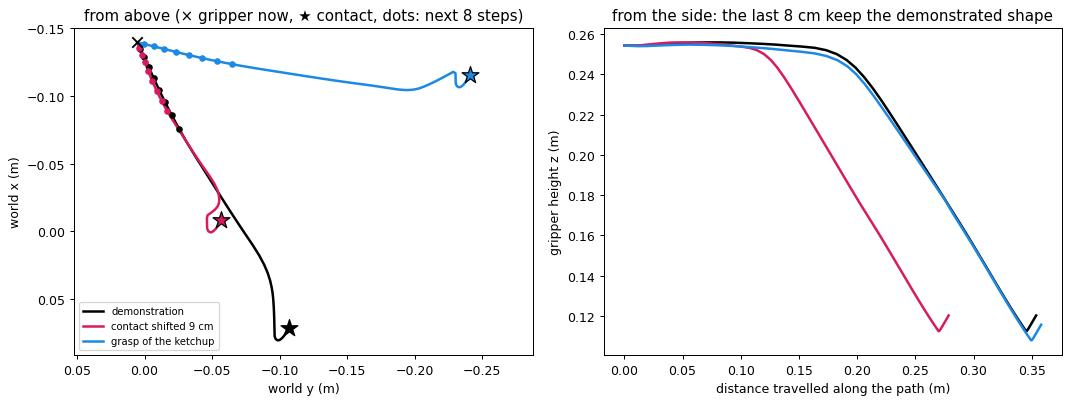

In [4]:
track = next(t for t in tracks if t.target == "salad_dressing_1")
step = 12
grasp = track.labels[0].contact
other = "ketchup_1"
contacts = {"contact shifted 9 cm": grasp + np.array([-0.08, 0.05, 0.0]),
            f"grasp of the {H.pretty(other)}": track.object_pos[step, track.names.index(other)] + contact.grasp[other]}
fig = P.moved_paths_figure(track, step, contacts, max_step=stats["motion_scale_m_per_unit"])
plt.show()

## 4 · Training
**This step:** the VLM is frozen. Trained are the plan network, low-rank updates (rank 16) of the attention and feed-forward layers of all 36 blocks of the action head, and its output layer. Each run goes through the GPU queue on one shared card.

**Status:** real. Every run has the plan input. The three runs on six tasks differ in the moved plans: none; moved plans with the path loss; moved plans supervised by relabelled actions instead (the flow-matching loss on the demonstrated command plus the correction, no path loss). Three earlier runs on one task (shifted contacts only, 1,200 steps) are kept as a first check; they used an earlier form of the target path (the travelled path instead of the commanded one). The right panel is the path loss during training (a Huber distance in cm on noisy one-step estimates); runs without it stay at zero.

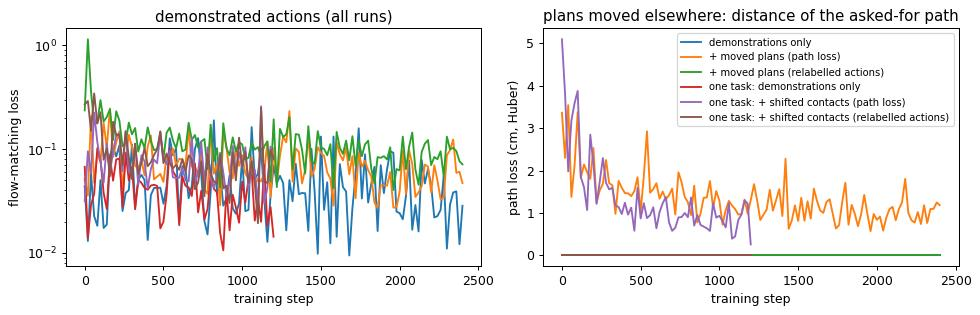

In [5]:
fig = P.training_figure(FOLDERS | FIRST)
plt.show()

## 5 · Open loop on held-out demonstrations
**This step:** on frames of demonstrations that were not used for training, sample a chunk (4 flow steps) and compare. `demo_action_error`: mean error of the translation actions against the demonstration (action units). `*_path_cm`: mean distance of the chunk's path to the moved path. `*_if_ignored`: the same distance for the demonstrated chunk, i.e. what a head that ignores the plan would score.

**Status:** real; no simulator. Before training the head scores like one that ignores the plan, as it must.

In [6]:
display(P.open_loop_table(FOLDERS | FIRST))

demo_action_error  \
run                                               training                      
demonstrations only                               before               0.0520   
                                                  after                0.0537   
+ moved plans (path loss)                         before               0.0519   
                                                  after                0.1129   
+ moved plans (relabelled actions)                before               0.0519   
                                                  after                0.0815   
one task: demonstrations only                     before               0.0477   
                                                  after                0.0488   
one task: + shifted contacts (path loss)          before               0.0477   
                                                  after                0.1122   
one task: + shifted contacts (relabelled actions) before               0.0477   
                                                  after                0.0680   

                                                            shift_path_cm  \
run                                               training                  
demonstrations only                               before           2.8267   
                                                  after            2.8027   
+ moved plans (path loss)                         before           2.9328   
                                                  after            1.3981   
+ moved plans (relabelled actions)                before           2.9328   
                                                  after            1.3533   
one task: demonstrations only                     before           3.4862   
                                                  after            3.5227   
one task: + shifted contacts (path loss)          before           3.4862   
                                                  after            1.2877   
one task: + shifted contacts (relabelled actions) before           3.4862   
                                                  after            1.5235   

                                                            shift_path_cm_if_ignored  \
run                                               training                             
demonstrations only                               before                      2.6640   
                                                  after                       2.6640   
+ moved plans (path loss)                         before                      2.7813   
                                                  after                       2.7813   
+ moved plans (relabelled actions)                before                      2.7813   
                                                  after                       2.7813   
one task: demonstrations only                     before                      3.3795   
                                                  after                       3.3795   
one task: + shifted contacts (path loss)          before                      3.3795   
                                                  after                       3.3795   
one task: + shifted contacts (relabelled actions) before                      3.3795   
                                                  after                       3.3795   

                                                            other_path_cm  \
run                                               training                  
demonstrations only                               before              NaN   
                                                  after               NaN   
+ moved plans (path loss)                         before           4.5157   
                                                  after            1.6137   
+ moved plans (relabelled actions)                before           4.5157   
                                                  after            1.5401 

## 6 · Closed loop: the 21 rollouts of the pipeline demo, now with the oracle plan
**This step:** the same starts and perturbations as on 10 Nov: 5 standard starts; 10 rollouts whose instruction names another object of the scene; 6 rollouts with the salad dressing moved by 4, 9 or 16 cm. At every query (every 8 steps) the simulator side sends the oracle plan: the grasp point of the named object while it is not held, the release point over the basket while it is, nothing once it lies in the basket.

**Status:** real rollouts; the plan is ORACLE. A rollout counts when the object named by the instruction is the first one grasped and ends in the basket. The first column is the released policy without any plan (10 Nov).

In [7]:
runs = {"released policy, no plan": P.load_run(BASELINE)}
runs |= {name: P.load_run(folder / "rollouts_oracle") for name, folder in FOLDERS.items()}
with_empty_plan = runs | {f"{MAIN}, empty plan in the rollout": P.load_run(FOLDERS[MAIN] / "rollouts_zero")}
display(P.success_table(with_empty_plan))

,"released policy, no plan",demonstrations only,+ moved plans (path loss),+ moved plans (relabelled actions),"+ moved plans (path loss), empty plan in the rollout"
standard,5 / 5,5 / 5,5 / 5,5 / 5,2 / 5
target moved 4–16 cm,1 / 6,1 / 6,2 / 6,6 / 6,1 / 6
another object named,2 / 10,2 / 10,7 / 10,7 / 10,0 / 10


**More start states.** Six and ten rollouts per set are few, so the two perturbed sets were repeated from four further start states (2–5) for the three trained policies: 12 more rollouts with the target moved and 20 more with another object named. The released policy without a plan was not run from these starts; "demonstrations only" stands in for it, since it scores like the released policy on the first 21. First table: the further starts alone. Second table: all starts together. Third table: how easily chance alone gives a difference of that size between two policies (Fisher's exact test). The test takes the rollouts as independent although the policies share start states, and the six comparisons are not corrected, so the p-values are a rough guide.

In [8]:
more = {name: P.load_run(folder / MORE) for name, folder in FOLDERS.items()}
both = {name: P.merge_runs(runs[name], more[name]) for name in FOLDERS}
display(P.success_table(more).drop(index="standard"))
display(P.success_table(both))
display(P.chance_table(both, [("demonstrations only", MAIN), ("demonstrations only", RELABELLED), (MAIN, RELABELLED)]))

,demonstrations only,+ moved plans (path loss),+ moved plans (relabelled actions)
target moved 4–16 cm,7 / 12,10 / 12,9 / 12
another object named,4 / 20,12 / 20,13 / 20


,demonstrations only,+ moved plans (path loss),+ moved plans (relabelled actions)
standard,5 / 5,5 / 5,5 / 5
target moved 4–16 cm,8 / 18,12 / 18,15 / 18
another object named,6 / 30,19 / 30,20 / 30


,target moved 4–16 cm,another object named
demonstrations only vs + moved plans (path loss),8/18 vs 12/18: p = 0.315,6/30 vs 19/30: p = 0.001
demonstrations only vs + moved plans (relabelled actions),8/18 vs 15/18: p = 0.035,6/30 vs 20/30: p = 0.001
+ moved plans (path loss) vs + moved plans (relabelled actions),12/18 vs 15/18: p = 0.443,19/30 vs 20/30: p = 1.000


**Where the rollouts stop.** Following the plan and finishing the task are different things, so each rollout of the three trained policies (all starts) is split into stages: did the gripper come within 2 cm of the planned grasp point (checked at every step against the contact of the latest plan), was the object knocked over before it was held (it sank more than 3 cm below its start height), was it held, was it in the basket at the end.

In [9]:
GROUPS = {name: (folder / "rollouts_oracle", folder / MORE) for name, folder in FOLDERS.items()}
for name in ("target moved 4–16 cm", "another object named"):
    print(name)
    display(P.stage_table(GROUPS, name))

target moved 4–16 cm


,rollouts,gripper came within 2 cm of the planned grasp point,object knocked over before it was held,object held,object delivered,"held, then let go outside the basket","held, still in the gripper at the end"
demonstrations only,18,6,5,8,8,0,0
+ moved plans (path loss),18,18,3,16,12,4,0
+ moved plans (relabelled actions),18,18,0,18,15,3,0


another object named


,rollouts,gripper came within 2 cm of the planned grasp point,object knocked over before it was held,object held,object delivered,"held, then let go outside the basket","held, still in the gripper at the end"
demonstrations only,30,6,0,6,6,0,0
+ moved plans (path loss),30,30,0,27,19,4,4
+ moved plans (relabelled actions),30,27,0,26,20,4,2


**How jerky the commands are.** Mean change of the translation command from one step to the next within a chunk, over the chunks requested before the gripper first touches an object (action units; the commands themselves average about 0.3). The path loss compares where the chunk ends up step by step, which leaves a jump forth and back between neighbouring steps almost unpunished.

In [10]:
display(P.roughness_table({"released policy, no plan": (BASELINE,)} | GROUPS))

,standard,target moved 4–16 cm,another object named
"released policy, no plan",0.032,0.040,0.033
demonstrations only,0.035,0.049,0.035
+ moved plans (path loss),0.149,0.155,0.170
+ moved plans (relabelled actions),0.069,0.084,0.096


Every rollout of the first 21, side by side.

In [11]:
for name in ("target moved 4–16 cm", "another object named"):
    print(name)
    display(P.outcome_details(runs, name))

target moved 4–16 cm


released policy, no plan: outcome  \
condition            start                                     
target shifted 4 cm  0                              no grasp   
                     1                              no grasp   
target shifted 9 cm  0                               success   
                     1                         not delivered   
target shifted 16 cm 0                              no grasp   
                     1                              no grasp   

                            released policy, no plan: steps  \
condition            start                                    
target shifted 4 cm  0                                  280   
                     1                                  280   
target shifted 9 cm  0                                  261   
                     1                                  280   
target shifted 16 cm 0                                  280   
                     1                                  280   

                           demonstrations only: outcome  \
condition            start                                
target shifted 4 cm  0                         no grasp   
                     1                         no grasp   
target shifted 9 cm  0                         no grasp   
                     1                          success   
target shifted 16 cm 0                         no grasp   
                     1                         no grasp   

                            demonstrations only: steps  \
condition            start                               
target shifted 4 cm  0                             280   
                     1                             280   
target shifted 9 cm  0                             280   
                     1                             169   
target shifted 16 cm 0                             280   
                     1                             280   

                           + moved plans (path loss): outcome  \
condition            start                                      
target shifted 4 cm  0                                success   
                     1                                success   
target shifted 9 cm  0                          not delivered   
                     1                          not delivered   
target shifted 16 cm 0                          not delivered   
                     1                               no grasp   

                            + moved plans (path loss): steps  \
condition            start                                     
target shifted 4 cm  0                                   111   
                     1                                   114   
target shifted 9 cm  0                                   280   
                     1                                   280   
target shifted 16 cm 0                                   280   
                     1                                   280   

                           + moved plans (relabelled actions): outcome  \
condition            start                                               
target shifted 4 cm  0                                         success   
                     1                                         success   
target shifted 9 cm  0                                         success   
                     1                                         success   
target shifted 16 cm 0                                         success   
                     1                                         success   

                            + moved plans (relabelled actions): steps  
condition            start                                             
target shifted 4 cm  0                                            114  
                     1                                            120  
target shifted 9 cm  0                                             98  
                     1                                            130  
target shift

another object named


released policy, no plan: outcome  \
condition                   start                                     
asked for the cream cheese  0                          wrong object   
                            1                          wrong object   
asked for the milk          0                          wrong object   
                            1                          wrong object   
asked for the alphabet soup 0                          wrong object   
                            1                          wrong object   
asked for the ketchup       0                               success   
                            1                               success   
asked for the tomato sauce  0                          wrong object   
                            1                          wrong object   

                                   released policy, no plan: steps  \
condition                   start                                    
asked for the cream cheese  0                                  121   
                            1                                  118   
asked for the milk          0                                  280   
                            1                                  280   
asked for the alphabet soup 0                                  280   
                            1                                  280   
asked for the ketchup       0                                  134   
                            1                                  139   
asked for the tomato sauce  0                                  113   
                            1                                  117   

                                  demonstrations only: outcome  \
condition                   start                                
asked for the cream cheese  0                     wrong object   
                            1                     wrong object   
asked for the milk          0                     wrong object   
                            1                     wrong object   
asked for the alphabet soup 0                     wrong object   
                            1                     wrong object   
asked for the ketchup       0                          success   
                            1                          success   
asked for the tomato sauce  0                     wrong object   
                            1                     wrong object   

                                   demonstrations only: steps  \
condition                   start                               
asked for the cream cheese  0                             120   
                            1                             117   
asked for the milk          0                             280   
                            1                             280   
asked for the alphabet soup 0                             280   
                            1                             280   
asked for the ketchup       0                             136   
                            1                             143   
asked for the tomato sauce  0                             115   
                            1                             119   

                                  + moved plans (path loss): outcome  \
condition                   start                                      
asked for the cream cheese  0                                success   
                            1                                success   
asked for the milk          0                                success   
                            1                          not delivered   
asked for the alphabet soup 0                                success   
                            1                               no grasp   
asked for the ketchup       0                                success   
                            1                                success   
asked for the tomato sauce  0                 

The first check, on one task with shifted contacts only (the "another object" set was not run). The first two adapters were evaluated twice: once with an oracle plan that switched on the raw finger-contact flag, which made the plan jump back to the grasp 6 times in 22 rollouts, and once with the plan held through contact losses shorter than 5 steps (used everywhere else in this notebook).

In [12]:
first_runs = {"released policy, no plan": runs["released policy, no plan"]}
first_runs |= {name: P.load_run(folder / "rollouts_oracle") for name, folder in FIRST.items()}
first_runs |= {f"{name}, first evaluation": P.load_run(folder / "rollouts_oracle_first")
               for name, folder in list(FIRST.items())[:2]}
display(P.success_table(first_runs).drop(index="another object named"))

,"released policy, no plan",one task: demonstrations only,one task: + shifted contacts (path loss),one task: + shifted contacts (relabelled actions),"one task: demonstrations only, first evaluation","one task: + shifted contacts (path loss), first evaluation"
standard,5 / 5,5 / 5,5 / 5,5 / 5,5 / 5,5 / 5
target moved 4–16 cm,1 / 6,1 / 6,6 / 6,6 / 6,0 / 6,6 / 6


Gripper paths from above for the two perturbed sets, first 21 rollouts (green: the named object was delivered; ★: where it starts).

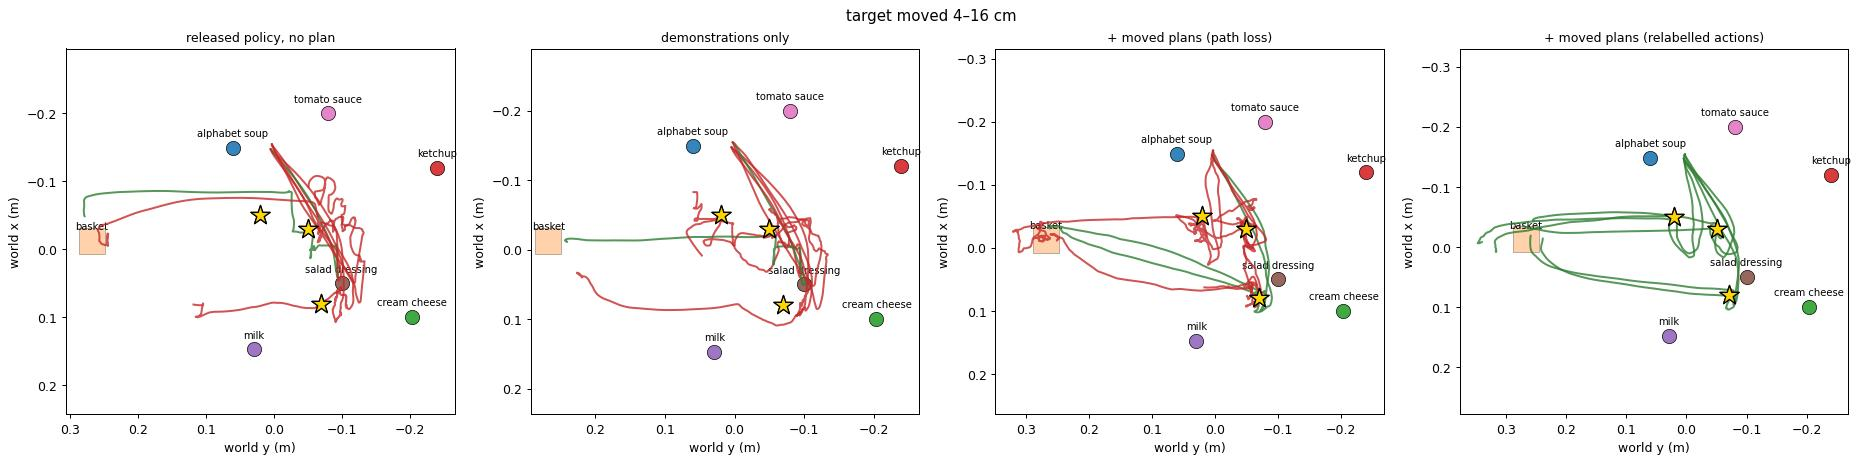

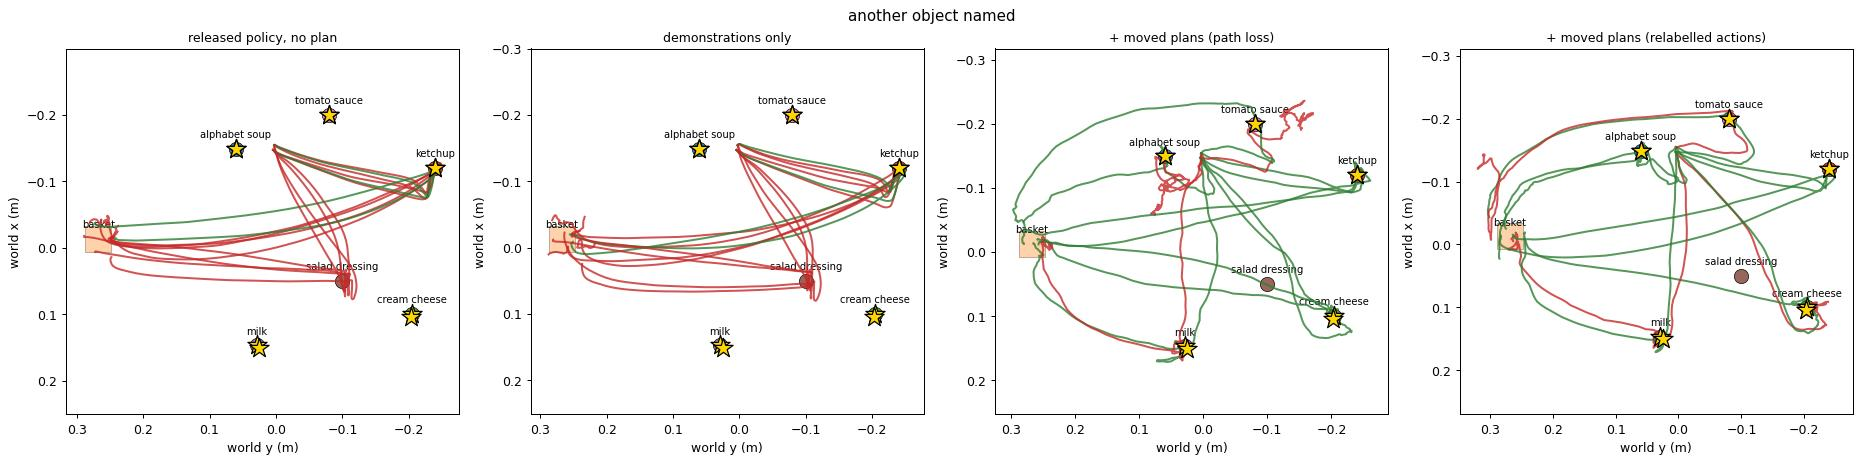

In [13]:
layout = runs["released policy, no plan"]["standard"][0]
fig = P.rollout_paths_figure(runs, P.SETS["target moved 4–16 cm"], layout)
fig.suptitle("target moved 4–16 cm", y=1.02)
plt.show()
fig = P.rollout_paths_figure(runs, P.SETS["another object named"], layout)
fig.suptitle("another object named", y=1.02)
plt.show()

Distance from the gripper to the planned contact at every query, perturbed rollouts of the first 21. It falls to zero at the grasp, jumps when the plan switches to the release point, and falls again. A line that stays flat above zero is a rollout that does not follow its plan.

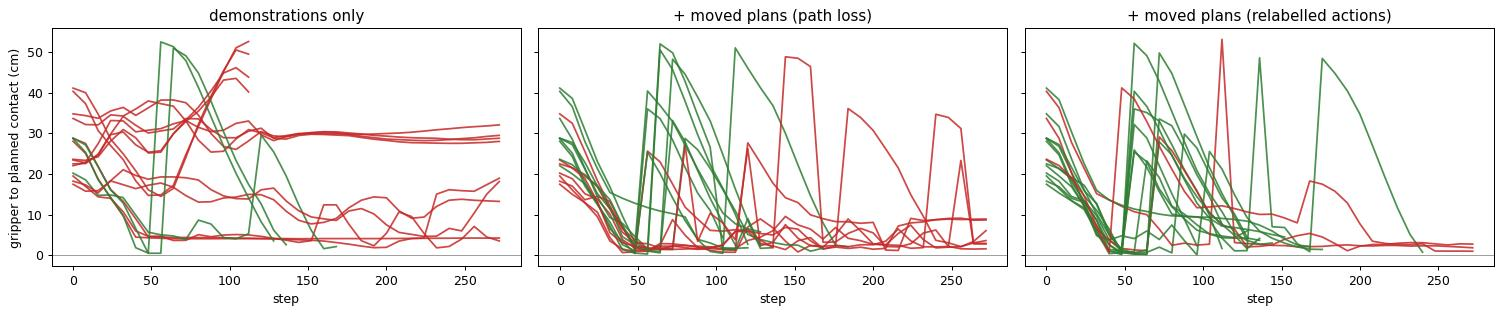

In [14]:
fig = P.reach_figure({name: folder / "rollouts_oracle" for name, folder in FOLDERS.items()},
                     P.SETS["target moved 4–16 cm"] + P.SETS["another object named"])
plt.show()

In [15]:
clip_logs = {"released policy, no plan": (BASELINE, "shift_16cm", 0)}
clip_logs |= {name: (folder / "rollouts_oracle", "shift_16cm", 0) for name, folder in FOLDERS.items()}
clip_logs |= {"moved plans (path loss): asked for the milk": (FOLDERS[MAIN] / "rollouts_oracle", "ask_milk", 0)}
logs = [H.load_rollout_log(folder / f"{tag}_ep{start}.npz") for folder, tag, start in clip_logs.values()]
CLIP = MEDIA / "plan_following_rollouts.mp4"
H.render_rollout_grid(logs, list(clip_logs), CLIP)
Video(str(CLIP), embed=True, width=1100)

## 7 · What we learned

**What this run shows**
- **Given only as an extra input, the plan is ignored.** The policy trained with the plan input on demonstrations alone behaves like the released one: the same counts on the first 21 rollouts (5/5, 1/6, 2/10). Over all starts its gripper comes within 2 cm of the planned grasp point in 6 of 18 rollouts with a moved target and in 6 of 30 that name another object. Open loop, its chunks are no closer to a moved path than chunks that ignore the plan (2.8 cm against 2.7 cm). In a demonstration the plan says nothing that the image does not already say.
- **Trained with moved plans, the head goes where the plan says.** The gripper reaches the planned grasp point in 18 of 18 rollouts with a moved target, with either form of supervision, and in 30 and 27 of 30 rollouts that name another object. Open loop, the distance to the moved path falls to 1.4–1.6 cm, from 2.8–4.8 cm for a head that ignores the plan.
- **The named object ends in the basket more often.** Another object named: 6 of 30 without moved plans, 19 of 30 with the path loss, 20 of 30 with relabelled actions (p ≈ 0.001 for both). Target moved: 8 of 18, then 12 and 15 of 18; with 18 rollouts only the 15 stands out from chance (p = 0.035; for the 12, p = 0.31). The p-values are rough: the policies share start states and the comparisons are not corrected. The standard starts stay at 5 of 5.
- **The policy now depends on its plan.** The path-loss policy with an empty plan gets 2 of 5 standard starts, 1 of 6 with a moved target and 0 of 10 with another object named. Whatever a predicted plan gets wrong will go straight into the actions.
- **What still fails, fails after the grasp.** The two policies trained with moved plans fail 30 of their 96 perturbed rollouts. In 9 the object was never held. In 21 it was held and then let go outside the basket (15) or was still in the gripper at step 280 (6). Moved plans were built only for the approach to a grasp; the carry and the release were trained on demonstrations alone.
- **The consistency loss is not what makes the head follow the plan.** Relabelled actions under the ordinary flow-matching loss do as well closed loop (35 of 48 perturbed rollouts against 31 of 48, p = 0.51) and open loop (1.35 and 1.54 cm against 1.40 and 1.61 cm). Here the moved path is built from the demonstration, so the path loss teaches what a relabelled action teaches, in a looser metric.
- **The path loss leaves jerky commands.** The translation command changes by 0.15–0.17 action units from one step to the next, against 0.07–0.10 with relabelled actions and 0.03–0.04 for the released policy. The error on held-out demonstrated actions is 0.113 against 0.082 (demonstrations only: 0.054). With the path loss the bottle was knocked over before the grasp in 3 of 18 moved-target rollouts, with relabelled actions in none.
- **Six rollouts per set were too few.** With the target moved, the first two starts gave 2 of 6 for the path loss and 6 of 6 for relabelled actions; four more starts gave 10 and 9 of 12. "Demonstrations only" went from 1 of 6 to 7 of 12: on the further starts it handles the 4 cm shift in 4 of 4 rollouts and the 16 cm shift in 0 of 4. The 1 of 6 reported for the released policy on 10 Nov would probably also be higher on other starts (not run).
- **Recorded simulator states give the labels directly.** Loading the stored states gives images, positions and finger contacts of exactly the recorded demonstration, with no replay drift and no failed replays. 267 of the 300 demonstrations of six tasks show exactly one grasp and one release of the target and were kept. This corrects risk 5 of Pipeline v2, which assumed contacts need the actions to be executed again.
- **In this checkpoint a plan token beside the head's own tokens would not be read.** The action head has no self-attention, so the plan is added to the action tokens. This answers the first question of the 10 Nov notebook for this checkpoint only.

**What it does not show**
- **Nothing about predicting plans.** The plan is an oracle: simulator ground truth plus the average grasp point of the demonstrations (spread about 1 cm).
- **Not the paper's configuration.** The VLM is frozen and is the 4B model; about 31 M parameters are trained for 2,400 steps.
- **One scene, one seed.** All rollouts are perturbations of one LIBERO-Object scene, with one training run per configuration and one sampling seed; a cell of the tables has 18 or 30 rollouts.
- **Only where the grasp happens.** The plan input and the losses constrain the position of the contact. The approach direction is an input but nothing checks that it is followed, and rotation is copied from the demonstration.
- **Whether the path loss can be repaired.** A smoothness term, or the path loss on top of relabelled actions, was not tried.
- **The first check is not comparable in detail.** The three runs on one task used the travelled path as the target instead of the commanded one.

**To decide together**
1. **What the method claims about the consistency loss.** My recommendation: make "training with moved plans" the core of the action half, with relabelled actions as the default supervision, and keep the differentiable consistency loss for the case where no action label can be written, which is a predicted plan whose error should flow back into the plan head. The alternative is to keep the path loss in front and first try to remove the jerkiness (one more run).
2. **The next experiment: the plan head.** Proposed order: predict the plan from the VLM's hidden states and measure the contact error in cm on held-out demonstrations and on moved scenes; then run this action head closed loop on predicted plans. Because the head now depends on its plan, the first number decides the second.
3. **Moved plans for the carry and the release.** 21 of the 30 remaining failures are there. Add them before the plan head, or after?
4. **How many rollouts per condition from now on.** Two starts per condition were misleading here. Six starts (18–30 rollouts per cell) cost about 10 minutes of one card per policy.